# Classifying with Sorted Spikes: TCM-SR in place of the continuous dynamic

This notebook follows tutorial 04 (`notebooks/tutorial/04-Classifying_with_Sorted_Spikes.ipynb`), but replaces its `continuous` dynamic with `tcm_sr`, a Temporal Context Model successor representation (`TCM_SR`) of the animal's own movement. `TCM_SR` contains the continuous dynamic as a special case, so nothing is lost: with `gamma=0`, `beta=1` and `asymmetry=1` it is exactly tutorial 04's `RandomWalk`, as shown below.

Unlike tutorial 04, every simulation here uses one set of settings (next section): the size of the place-cell population, running and replay speeds, the decoding bin, and the firing rate during replay. All replays are made the same way, as a trajectory plus spikes drawn from the place fields along it.

### Set Plotting Defaults

In [1]:
%load_ext autoreload
%autoreload 2

import logging
import os

import matplotlib
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

# Set background and fontsize
rc_params = {
    'pdf.fonttype': 42, # Make fonts editable in Adobe Illustrator
    'ps.fonttype': 42, # Make fonts editable in Adobe Illustrator
    'axes.labelcolor': '#222222',
    'axes.labelsize': 9,
    'text.color': '#222222',
    'font.sans-serif' : 'Helvetica',
    'text.usetex': False,
    'figure.figsize': (7.2, 4.45),
    'xtick.major.size': 0.00,
    'ytick.major.size': 0.00,
    'axes.labelpad': 0.1,
    }
sns.set(style='white', context='paper', rc=rc_params,
        font_scale=1.0)

# Make analysis reproducible
np.random.seed(0)

# Enable logging
logging.basicConfig(level=logging.INFO)

## Settings

Every simulation in the notebook uses these. They live in `tcmsr_simulation_config.py`, next to this notebook, and are shared with `Fitting_TCM_SR_with_EM.ipynb`: change them there and rerun. The simulation code itself is in `tcmsr_simulation.py`.

* `RUNNING_SPEED_CM_S` is the mean speed of the simulated laps. Each run from one end of the track to the other has its own speed, drawn with a coefficient of variation of `RUNNING_SPEED_CV`. Within a run the position follows a half cosine, so the peak speed is $\pi/2$ times that run's speed.
* Replays run `REPLAY_SPEEDUP` times faster than that.
* Replay spikes are Poisson, from Gaussian place fields with a peak of `REPLAY_PEAK_RATE_HZ`. With `IDEALIZED_SPIKES = True` the nearest place cell instead spikes once every bin, which gives clean, tutorial-style figures.

In [2]:
from tcmsr_simulation_config import *
from tcmsr_simulation_config import print_settings

N_RECOVERY_EVENTS = 20      # events per generating dynamic in the recovery test
print_settings()

N_CELLS = 100
RUNNING_SPEED_CM_S = 80.0
RUNNING_SPEED_CV = 0.25
N_LAPS = 50
REPLAY_SPEEDUP = 10
DECODE_BIN_S = 0.003
PLACE_BIN_SIZE_CM = 2.0
REPLAY_PEAK_RATE_HZ = 20.0
EVENT_S = 0.2
IDEALIZED_SPIKES = False


## Simulate Sorted Spikes Data

First let's simulate some data to train the encoding model on. The animal runs back and forth on the track, each run at its own speed, sampled at 1 kHz, and each place cell fires at up to 15 Hz in its field while it runs. Half the cells fire only on the way out and half only on the way back. Position and spikes are then binned to the decoding bin.

100 cells, 78043 bins of 3 ms (234 s of running)


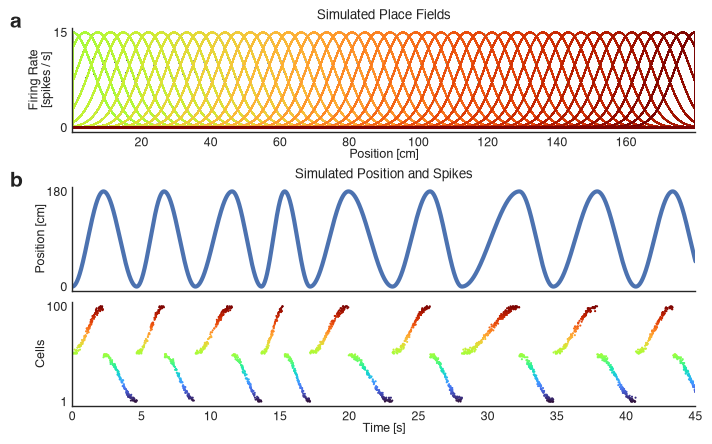

In [3]:
from tcmsr_simulation import simulate_run_data

MM_TO_INCHES = 1.0 / 25.4
TWO_COLUMN = 178.0 * MM_TO_INCHES
GOLDEN_RATIO = (np.sqrt(5) - 1.0) / 2.0

run = simulate_run_data()
time, linear_distance, spikes, place_fields = run.time, run.linear_distance, run.spikes, run.place_fields
track_length, place_field_means = run.track_length, run.place_field_means
sampling_frequency = run.sampling_frequency
n_bins = time.size
print(f'{N_CELLS} cells, {n_bins} bins of {1e3 * DECODE_BIN_S:g} ms ({time[-1]:.0f} s of running)')

spike_ind, neuron_ind = np.nonzero(spikes)
colors = plt.get_cmap('turbo')(np.linspace(0, 1, spikes.shape[1]))
lap_s = 2 * track_length / RUNNING_SPEED_CM_S
plot_s = min(10 * lap_s, time[-1])

fig, axes = plt.subplots(3, 1, figsize=(TWO_COLUMN, TWO_COLUMN * GOLDEN_RATIO), constrained_layout=True)
for place_field, color in zip(place_fields.T, colors):
    axes[0].plot(linear_distance, place_field, linewidth=1, color=color)
axes[0].set_xlabel('Position [cm]')
axes[0].set_ylabel('Firing Rate\n[spikes / s]')
axes[0].set_title('Simulated Place Fields')
axes[0].set_xlim((linear_distance.min(), linear_distance.max()))
axes[0].set_yticks([0, np.round(place_fields.max())])
axes[0].text(-0.10, 1.0, 'a', transform=axes[0].transAxes,
        size=15, weight='extra bold')

axes[1].plot(time, linear_distance, linewidth=3)
axes[1].set_ylabel('Position [cm]')
axes[1].set_title('Simulated Position and Spikes')
axes[1].set_yticks([0, np.round(linear_distance.max())])
axes[1].set_xticks([])
axes[1].set_xlim((0.0, plot_s))
axes[1].text(-0.10, 1.0, 'b', transform=axes[1].transAxes,
        size=15, weight='extra bold')

c = [colors[ind] for ind in neuron_ind]
axes[2].scatter(time[spike_ind], neuron_ind + 1, c=c, s=0.5)
axes[2].set_yticks((1, spikes.shape[1]))
axes[2].set_ylabel('Cells')

axes[2].set_xlabel('Time [s]')
axes[2].set_xlim((0.0, plot_s))

sns.despine()

### Unfold the track into one directed loop

The animal runs the track in both directions, and the neurons are direction selective. Instead of a separate state space per direction, we unfold the track into a single loop of twice its length $L$:

$$u = \begin{cases} x & \text{running outbound (}x\text{ increasing)} \\ 2L - x & \text{running inbound} \end{cases}$$

Running now always *increases* $u$: from 0 to $L$ going out, on to $2L$ coming back, then wrapping to 0. The two branches meet at the far end ($x = L$ gives $u = L$ either way), so the turnaround is continuous; the start end is where $u$ wraps.

Two things follow:

- Every observed movement points forward in $u$, so a single `TCM_SR` kernel fit on $u$ is directed everywhere. Because `TCM_SR` is built from observed transitions rather than distances, it also follows the wrap from $2L$ back to 0. (`RandomWalk`, being Euclidean, would not.)
- An outbound neuron only fires on $[0, L]$ and an inbound neuron only on $[L, 2L]$, so an ordinary place-field fit on $u$ learns each direction-selective field in its own half, with no encoding groups.

The latent state is therefore (dynamic, $u$), which is (dynamic, position, direction).

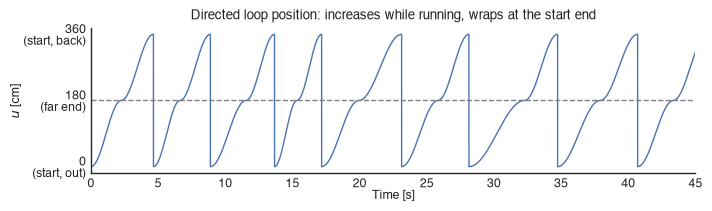

In [4]:
directional_position = run.directional_position

fig, ax = plt.subplots(figsize=(TWO_COLUMN, 2), constrained_layout=True)
ax.plot(time, directional_position, linewidth=1)
ax.axhline(track_length, color='grey', linestyle='--', linewidth=1)
ax.set_xlim((0.0, plot_s))
ax.set_yticks([0, track_length, 2 * track_length])
ax.set_yticklabels(['0\n(start, out)', f'{track_length:.0f}\n(far end)', f'{2 * track_length:.0f}\n(start, back)'])
ax.set_xlabel('Time [s]')
ax.set_ylabel('$u$ [cm]')
ax.set_title('Directed loop position: increases while running, wraps at the start end')
sns.despine()

## Fit Sorted Spikes Classifier

Next we will fit the model on the position and the spikes. This will encode the relationship between spikes and position (aka the place field maps).

The `continuous_transition_types` parameter is a 3x3 matrix (because we have three dynamics: tcm_sr, fragmented, and stationary). Rows are the previous dynamic and columns the current one. This governs how the position will change when in a given dynamic or when transitioning between dynamics. A transition *into* a dynamic uses that dynamic's kernel, except that leaving the fragmented dynamic is always `Uniform()`, because a fragmented position says nothing about where the next one will be.

The `tcm_sr` dynamic takes the place of tutorial 04's `continuous` dynamic. Where `RandomWalk` scores a step by the Euclidean distance between bins, `TCM_SR` scores it by how reachable one bin is from another given the transitions the animal actually made. From the row-stochastic empirical movement matrix $P$ it builds the successor representation $M$ and mixes in a retrieved-context term:

$$M = (I - \gamma P)^{-1} P, \qquad A = \text{asymmetry} \cdot M + (1 - \text{asymmetry})\, M^\top M$$

(each term row normalized when `asymmetry` is set). Its parameters move it between the continuous dynamic and the animal's own behavior:

- `beta` blends a local `RandomWalk` of variance `local_movement_var` into $P$. At `beta=1`, $P$ *is* that random walk.
- `gamma` is the look-ahead, counted in steps of $P$: the mean horizon is $1 / (1 - \gamma)$ steps. At `gamma=0`, $M = P$, a single step.
- `asymmetry=1` keeps only the directional term $M$.

So `TCM_SR(gamma=0, beta=1, asymmetry=1, local_movement_var=v)` is exactly `RandomWalk(movement_var=v)`. Lowering `beta` replaces Euclidean distance with the animal's movement, and raising `gamma` extends it to a multi-step look-ahead.

**The step of $P$ sets the replay speed.** $P$ counts where the animal goes in `movement_time_step` seconds, and the decoder takes one step of the kernel per decoding bin. So at `gamma=0` the kernel replays behavior `movement_time_step / DECODE_BIN_S` times faster than it happened. We set `movement_time_step = REPLAY_SPEEDUP * DECODE_BIN_S` so that, at `gamma=0`, the kernel moves at the replay speed. Raising `gamma` makes it reach further each bin: `gamma=0.7` is a mean horizon of about 3.3 steps.

The `discrete_transition_diag` also creates a transition matrix between dynamics, defining how likely the model is, on average, to stay in the dynamic or change.

In [5]:
from replay_trajectory_classification import (
    SortedSpikesClassifier, Environment, TCM_SR,
    Uniform, Identity, estimate_movement_var)

# From linear position: the wraps in u would inflate the movement variance.
movement_var = estimate_movement_var(linear_distance, sampling_frequency)

environment = Environment(place_bin_size=PLACE_BIN_SIZE_CM)
state_names = ['tcm_sr', 'fragmented', 'stationary']
# One step of P per decoding bin replays behavior REPLAY_SPEEDUP times faster.
tcm_sr = TCM_SR(gamma=0.8, asymmetry=0.5,
                movement_time_step=REPLAY_SPEEDUP * DECODE_BIN_S,
                sampling_frequency=sampling_frequency)
continuous_transition_types = [[tcm_sr,    Uniform(), Identity()],
                               [Uniform(), Uniform(), Uniform() ],
                               [tcm_sr,    Uniform(), Identity()],
                              ]
classifier = SortedSpikesClassifier(
    environments=environment,
    continuous_transition_types=continuous_transition_types,
    sorted_spikes_algorithm='spiking_likelihood_kde',
    sorted_spikes_algorithm_params={'position_std': 3.0,
                                   }
)
# Fit on the directed loop position u, not on linear position.
classifier.fit(directional_position, spikes)

,environments,"(Environment(e...t_threshold=0),)"
,observation_models,"(ObservationMo...oding_group=0), ...)"
,continuous_transition_types,"[[TCM_SR(enviro...333, learn=()), Uniform(envir...nt2_name=None), ...], [Uniform(envir...nt2_name=None), Uniform(envir...nt2_name=None), ...], ...]"
,sorted_spikes_algorithm_params,{'position_std': 3.0}
,discrete_transition_type,DiagonalDiscr...al_value=0.98)
,initial_conditions_type,UniformInitialConditions()
,infer_track_interior,True
,sorted_spikes_algorithm,'spiking_likelihood_kde'
Name,Type,Value
continuous_state_transition_,"ndarray[float64](3, 3, 180, 180)","[[[[0.35,0.14,0.07,...,0.03,0.04,0.1 ], [0.1 ,0.16,0.17,...,0.02,0.03,0.07], [0.06,0.06,0.13,...,0.01,0.02,0.04], ..., [0.1 ,0.03,0.01,...,0.12,0.22,0.23], [0.14,0.04,0.02,...,0.06,0.17,0.33], [0.22,0.06,0.03,...,0.04,0.07,0.37]], [[0.01,0.01,0.01,...,0.01,0.01,0.01], [0.01,0.01,0.01,...,0.01,0.01,0.01], [0.01,0.01,0.01,...,0.01,0.01,0.01], ..., [0.01,0.01,0.01,...,0.01,0.01,0.01], [0.01,0.01,0.01,...,0.01,0.01,0.01], [0.01,0.01,0.01,...,0.01,0.01,0.01]], [[1. ,0. ,0. ,...,0. ,0. ,0. ], [0. ,1. ,0. ,...,0. ,0. ,0. ], [0. ,0. ,1. ,...,0. ,0. ,0. ], ..., [0. ,0. ,0. ,...,1. ,0. ,0. ], [0. ,0. ,0. ,...,0. ,1. ,0. ], [0. ,0. ,0. ,...,0. ,0. ,1. ]]], [[[0.01,0.01,0.01,...,0.01,0.01,0.01], [0.01,0.01,0.01,...,0.01,0.01,0.01], [0.01,0.01,0.01,...,0.01,0.01,0.01], ..., [0.01,0.01,0.01,...,0.01,0.01,0.01], [0.01,0.01,0.01,...,0.01,0.01,0.01], [0.01,0.01,0.01,...,0.01,0.01,0.01]], [[0.01,0.01,0.01,...,0.01,0.01,0.01], [0.01,0.01,0.01,...,0.01,0.01,0.01], [0.01,0.01,0.01,...,0.01,0.01,0.01], ..., [0.01,0.01,0.01,...,0.01,0.01,0.01], [0.01,0.01,0.01,...,0.01,0.01,0.01], [0.01,0.01,0.01,...,0.01,0.01,0.01]], [[0.01,0.01,0.01,...,0.01,0.01,0.01], [0.01,0.01,0.01,...,0.01,0.01,0.01], [0.01,0.01,0.01,...,0.01,0.01,0.01], ..., [0.01,0.01,0.01,...,0.01,0.01,0.01], [0.01,0.01,0.01,...,0.01,0.01,0.01], [0.01,0.01,0.01,...,0.01,0.01,0.01]]], [[[0.35,0.14,0.07,...,0.03,0.04,0.1 ], [0.1 ,0.16,0.17,...,0.02,0.03,0.07], [0.06,0.06,0.13,...,0.01,0.02,0.04], ..., [0.1 ,0.03,0.01,...,0.12,0.22,0.23], [0.14,0.04,0.02,...,0.06,0.17,0.33], [0.22,0.06,0.03,...,0.04,0.07,0.37]], [[0.01,0.01,0.01,...,0.01,0.01,0.01], [0.01,0.01,0.01,...,0.01,0.01,0.01], [0.01,0.01,0.01,...,0.01,0.01,0.01], ..., [0.01,0.01,0.01,...,0.01,0.01,0.01], [0.01,0.01,0.01,...,0.01,0.01,0.01], [0.01,0.01,0.01,...,0.01,0.01,0.01]], [[1. ,0. ,0. ,...,0. ,0. ,0. ], [0. ,1. ,0. ,...,0. ,0. ,0. ], [0. ,0. ,1. ,...,0. ,0. ,0. ], ..., [0. ,0. ,0. ,...,1. ,0. ,0. ], [0. ,0. ,0. ,...,0. ,1. ,0. ], [0. ,0. ,0. ,...,0. ,0. ,1. ]]]]"
discrete_state_transition_,"ndarray[float64](3, 3)","[[0.98,0.01,0.01], [0.01,0.98,0.01], [0.01,0.01,0.98]]"


We can plot the place fields (every tenth cell).

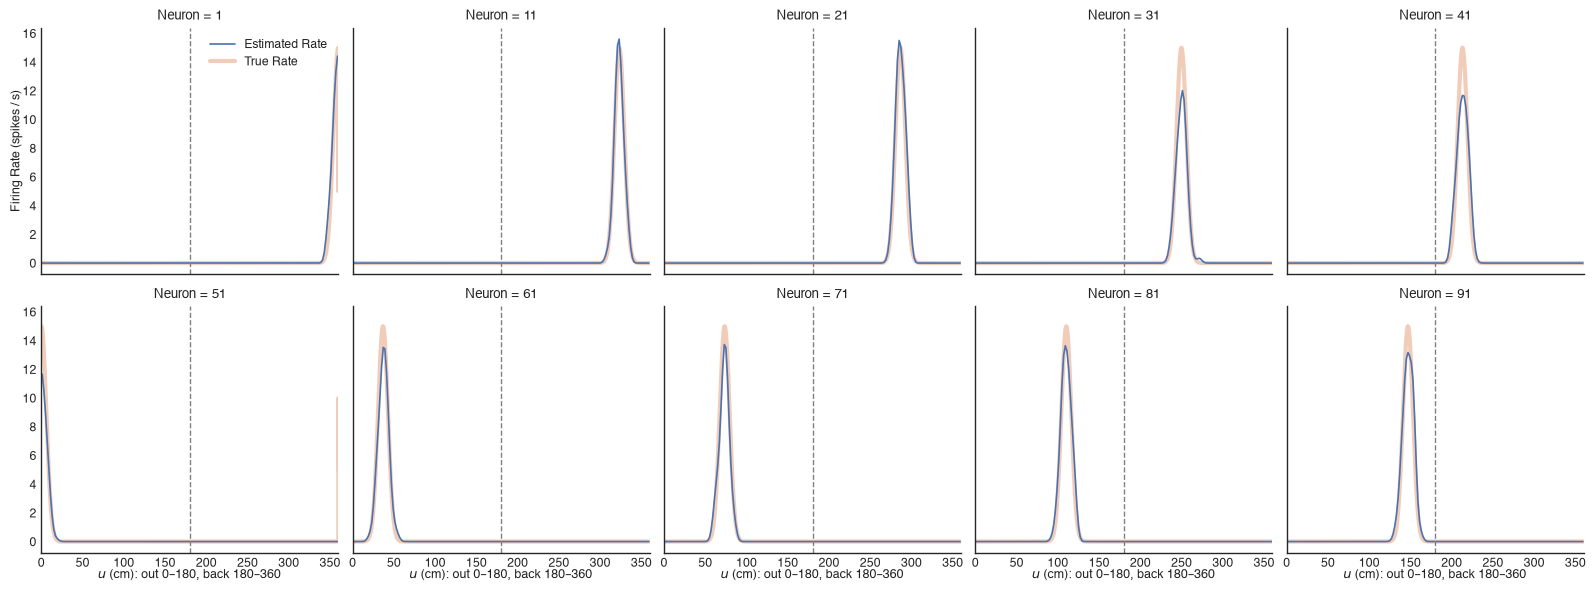

In [6]:
order = np.argsort(directional_position)[::20]  # subsample for plotting
shown = np.arange(0, N_CELLS, 10)
g = (classifier.place_fields_['', 0].isel(neuron=shown) * sampling_frequency).plot(
    x='position', col='neuron', col_wrap=5, label='Estimated Rate')
for ax, ind in zip(g.axes.flat, shown):
    ax.plot(directional_position[order], place_fields[order, ind], linestyle='-',
            zorder=0, linewidth=3, alpha=0.4, label='True Rate')
    ax.axvline(track_length, color='grey', linestyle='--', linewidth=1)
    ax.set_xlim((0, 2 * track_length))
    ax.set_title(f'Neuron = {ind + 1}')
sns.despine()

g.axes[0, 0].set_ylabel('Firing Rate (spikes / s)')
g.axes[0, 0].legend(frameon=False)

for ax in g.axes[-1]:
    ax.set_xlabel('$u$ (cm): out 0–180, back 180–360')

`TCM_SR` contains tutorial 04's continuous dynamic. With `gamma=0`, `beta=1` and `asymmetry=1` it is exactly a `RandomWalk`; the assertion below checks that to machine precision for a random walk whose standard deviation is about 1.4 replay steps per bin, the same ratio as tutorial 04 (6 cm² for 1.8 cm steps). The plot shows the distribution of the current position when the previous position is the middle of the outbound half of the loop, for that reduction and for the `tcm_sr` kernel the classifier uses.

max |TCM_SR(gamma=0, beta=1, asymmetry=1) - RandomWalk| = 1.1102230246251565e-16
replay step: 2.4 cm per bin
fitted tcm_sr from mid-outbound: forward 0.75, backward 0.21, stay 0.04, mean step +10.1 cm
one step of P from mid-outbound: 90% of its mass in 2 bins


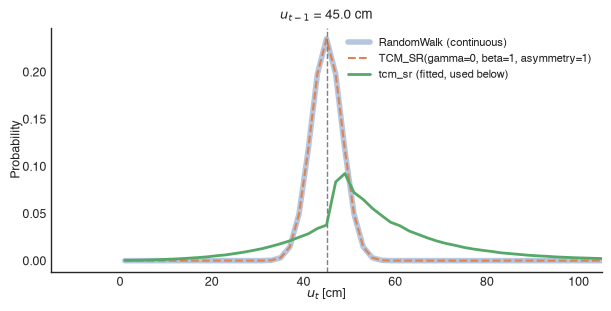

In [7]:
from replay_trajectory_classification import RandomWalk

replay_step_cm = REPLAY_SPEEDUP * RUNNING_SPEED_CM_S * DECODE_BIN_S
random_walk = RandomWalk(movement_var=2.0 * replay_step_cm ** 2)
tcm_sr_as_random_walk = TCM_SR(gamma=0.0, beta=1.0, asymmetry=1.0,
                               local_movement_var=random_walk.movement_var)

random_walk_kernel = random_walk.make_state_transition((environment,))
reduced_kernel = tcm_sr_as_random_walk.make_state_transition(
    (environment,), directional_position[:, np.newaxis])
np.testing.assert_allclose(reduced_kernel, random_walk_kernel, atol=1e-12)
print('max |TCM_SR(gamma=0, beta=1, asymmetry=1) - RandomWalk| =',
      np.abs(reduced_kernel - random_walk_kernel).max())

bin_centers = environment.place_bin_centers_.squeeze()
mid_bin = int(np.argmin(np.abs(bin_centers - track_length / 2))) // 2

fig, ax = plt.subplots(figsize=(6, 3), constrained_layout=True)
ax.plot(bin_centers, random_walk_kernel[mid_bin], linewidth=4, alpha=0.4,
        label='RandomWalk (continuous)')
ax.plot(bin_centers, reduced_kernel[mid_bin], linewidth=1.5, linestyle='--',
        label='TCM_SR(gamma=0, beta=1, asymmetry=1)')
ax.plot(bin_centers, classifier.continuous_state_transition_[0, 0, mid_bin], linewidth=2,
        label='tcm_sr (fitted, used below)')
ax.axvline(bin_centers[mid_bin], color='grey', linestyle='--', linewidth=1)
ax.set_xlim((bin_centers[mid_bin] - 60, bin_centers[mid_bin] + 60))
ax.set_xlabel(r'$u_{t}$ [cm]')
ax.set_ylabel('Probability')
ax.set_title(rf'$u_{{t-1}}$ = {bin_centers[mid_bin]:.1f} cm')

fitted_row = classifier.continuous_state_transition_[0, 0, mid_bin]
step = bin_centers - bin_centers[mid_bin]
print(f'replay step: {replay_step_cm:.1f} cm per bin')
print(f'fitted tcm_sr from mid-outbound: forward {fitted_row[step > 0].sum():.2f}, '
      f'backward {fitted_row[step < 0].sum():.2f}, stay {fitted_row[step == 0].sum():.2f}, '
      f'mean step {(fitted_row * step).sum():+.1f} cm')
one_step = TCM_SR(gamma=0.0, asymmetry=1.0, movement_time_step=tcm_sr.movement_time_step,
                  sampling_frequency=sampling_frequency).make_state_transition(
    (environment,), directional_position[:, np.newaxis])[mid_bin]
n_bins_90 = np.searchsorted(np.cumsum(np.sort(one_step)[::-1]), 0.9) + 1
print(f'one step of P from mid-outbound: 90% of its mass in {n_bins_90} bins')
ax.legend(frameon=False, fontsize=8)
sns.despine()

After we have fit the model, we can plot transition matrices that were constructed as specified by `continuous_transition_types`.

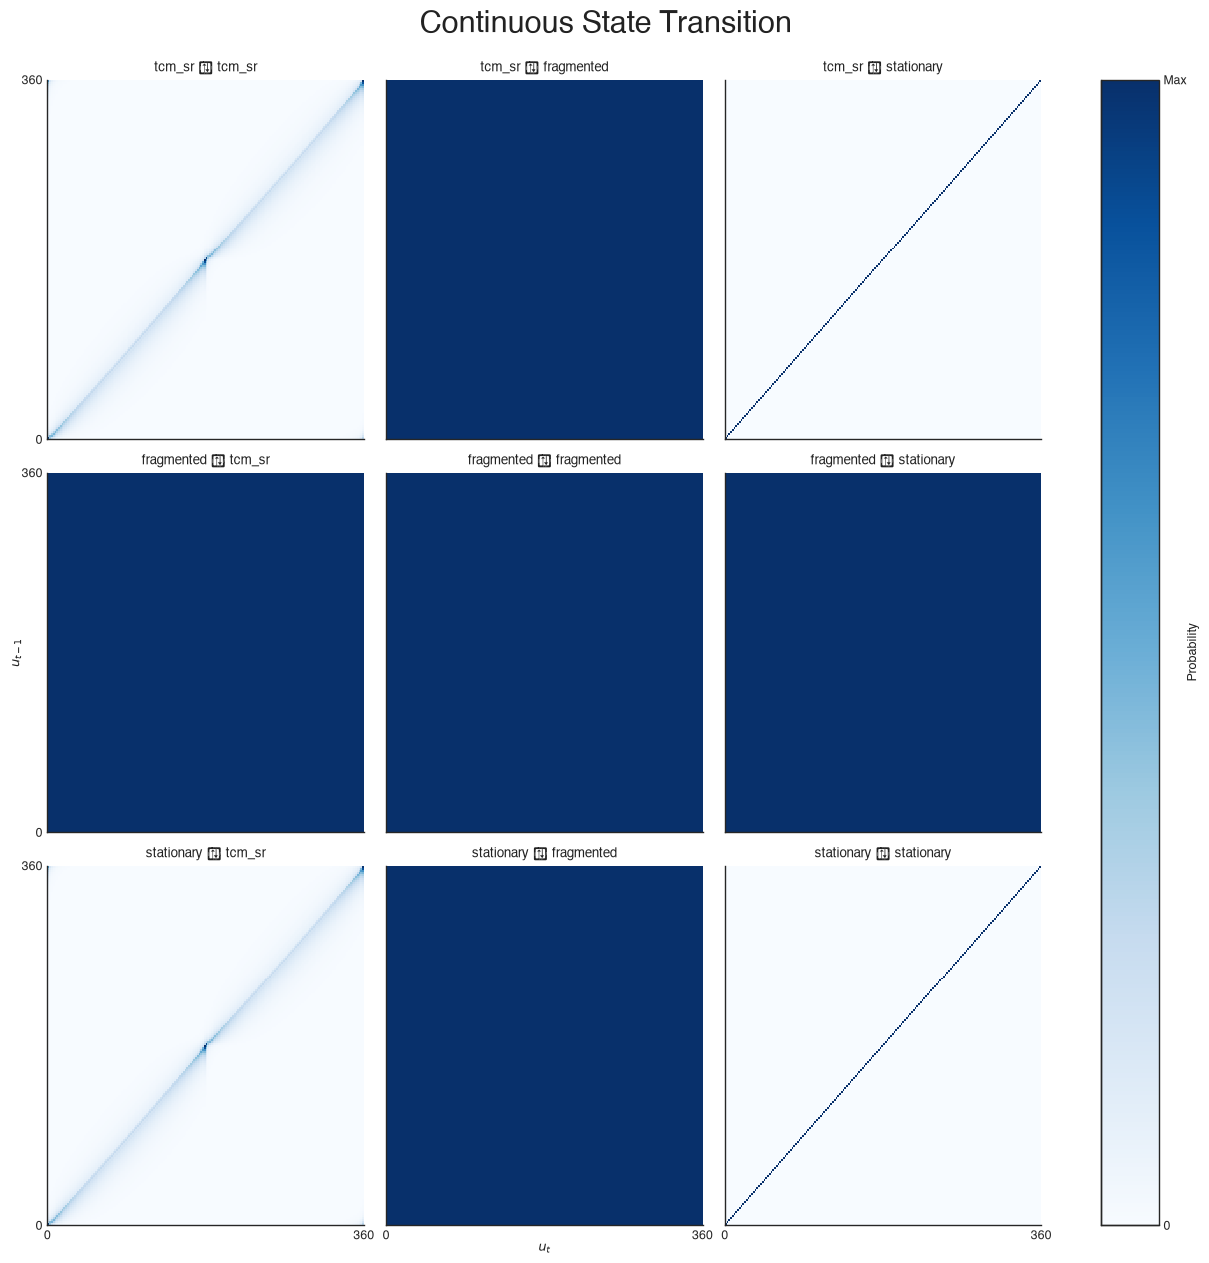

In [8]:
n_states = len(state_names)
fig, axes = plt.subplots(n_states, n_states, figsize=(12, 12),
                         sharex=True, sharey=True,
                         constrained_layout=True)
continuous_transition_types = np.asarray(classifier.continuous_transition_types)
x, y = np.meshgrid(environment.place_bin_edges_, environment.place_bin_edges_)
bin_min, bin_max = 0.0, 2 * track_length

for j in range(n_states):
    for k in range(n_states):
        im = axes[j, k].pcolormesh(x, y, classifier.continuous_state_transition_[j, k], cmap='Blues',
                                   vmin=0.0, vmax=classifier.continuous_state_transition_[j, k].max())
        # axes[j, k].text(1, 175, continuous_transition_types[j, k].replace('_', ' '), color='grey',
        #                 va='top', fontsize=14)
        axes[j, k].set_title(f'{state_names[j]} → {state_names[k]}')
        axes[j, k].set_xticks((bin_min, bin_max))
        axes[j, k].set_yticks((bin_min, bin_max))
        
plt.xlim((bin_min, bin_max))
plt.ylim((bin_min, bin_max))
axes[n_states // 2, 0].set_ylabel(r'$u_{t-1}$')
axes[-1, n_states // 2].set_xlabel(r'$u_{t}$')
plt.suptitle('Continuous State Transition', y=1.04, fontsize=22)
cbar = fig.colorbar(im, ax=axes.ravel().tolist(), ticks=[0, 1], label='Probability')
cbar.ax.set_yticklabels(['0', 'Max'])
sns.despine()

We can also plot the transition matrix between the dynamics

Text(0.5, 1.0, 'Discrete State Transition')

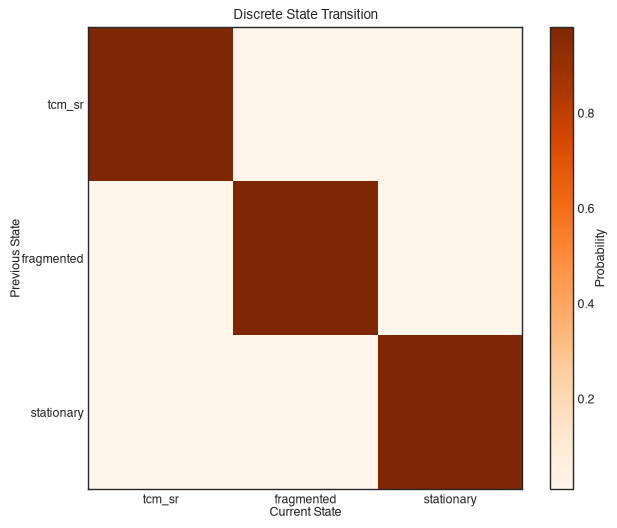

In [9]:
n_states = len(state_names)
edges = np.arange(0.5, n_states + 1.5)
x_edges, y_edges = np.meshgrid(edges, edges)
plt.figure(figsize=(7, 6))
plt.pcolormesh(x_edges, y_edges, np.fliplr(classifier.discrete_state_transition_), cmap='Oranges')
plt.xticks(ticks=range(1, n_states + 1), labels=state_names)
plt.yticks(ticks=range(1, n_states + 1), labels=state_names[::-1])
plt.colorbar(label='Probability')
plt.ylabel('Previous State')
plt.xlabel('Current State')
plt.title('Discrete State Transition')

## Test classifier on different replay types

Now we can see how this model works on different types of replay dynamics. Each replay is a trajectory on the loop, one position per decoding bin, turned into spikes the same way:

* **Continuous:** a constant-speed sweep at `REPLAY_SPEEDUP` times the running speed.
* **Stationary:** one fixed position.
* **Fragmented:** an independent random position every bin.
* **TCM-SR:** a Markov chain sampled from the classifier's own `tcm_sr` kernel.

Mixed replays join these end to end. Each piece is `EVENT_S` long, except that the stationary and fragmented pieces on either side of a mixed replay are half that. The red dots in the bottom panel are the true trajectory.

In [10]:
from tcmsr_simulation import ReplayPaths, make_replay_spikes

STATE_COLORS = {
    'stationary': '#9f043a',
    'fragmented': '#ff6944',
    'continuous': '#521b65',
    'tcm_sr': '#1b9e77',
    'stationary-continuous-mix': '#61c5e6',
    'fragmented-continuous-mix': '#2a586a',
    '': '#c7c7c7',
}

LOOP_LENGTH = 2 * track_length
n_event_bins = int(round(EVENT_S / DECODE_BIN_S))
# The classifier's own tcm_sr -> tcm_sr kernel, which the TCM-SR replays are sampled from.
tcm_sr_kernel = classifier.continuous_state_transition_[0, 0]
paths = ReplayPaths(environment, LOOP_LENGTH, kernel=tcm_sr_kernel)
interior_centers = paths.interior_centers


def sweep_path(start_u, n_time=n_event_bins):
    return paths.sweep(start_u, replay_step_cm, n_time)


def stationary_path(u, n_time=n_event_bins):
    return paths.stationary(u, n_time)


def fragmented_path(rng, n_time=n_event_bins):
    return paths.fragmented(rng, n_time)


def tcm_sr_path(start_u, rng, n_time=n_event_bins):
    return paths.tcm_sr(start_u, rng, n_time)


def make_spikes(u, rng):
    return make_replay_spikes(u, rng, place_field_means, track_length)


def classify(u, seed=0, clf=None, names=None):
    clf = classifier if clf is None else clf
    names = state_names if names is None else names
    test_spikes = make_spikes(u, np.random.default_rng(seed))
    event_time = np.arange(u.size) / sampling_frequency
    return event_time, test_spikes, clf.predict(test_spikes, time=event_time, state_names=names)


def plot_classification(event_time, test_spikes, results, true_u=None):
    fig, axes = plt.subplots(3, 1, figsize=(10, 6), constrained_layout=True, sharex=True)
    time_ms = 1e3 * event_time
    spike_time_ind, neuron_ind = np.nonzero(test_spikes)
    axes[0].scatter(time_ms[spike_time_ind], neuron_ind, color='black', zorder=1,
                    marker='|', s=80, linewidth=3)
    axes[0].axhline(N_CELLS // 2 - 0.5, color='grey', linewidth=0.5)
    axes[0].set_yticks((0, test_spikes.shape[1]))
    axes[0].set_ylabel('Neuron Index\n(inbound | outbound)')
    replay_probability = results.acausal_posterior.sum('position')
    for state, prob in replay_probability.groupby('state'):
        axes[1].plot(time_ms, prob.values.ravel(), linewidth=4, label=state,
                     color=STATE_COLORS[state])
    axes[1].set_ylabel('Probability')
    axes[1].set_yticks([0, 1])
    axes[1].set_ylim((-0.01, 1.05))
    axes[1].legend(bbox_to_anchor=(1.15, 0.95), loc='upper right', fancybox=False, shadow=False,
                   ncol=1, frameon=False)

    position_posterior = results.acausal_posterior.sum('state')
    axes[2].pcolormesh(time_ms, position_posterior.position, position_posterior.values.T,
                       vmin=0.0, vmax=np.quantile(position_posterior.values, 0.99),
                       shading='nearest', cmap='Purples')
    if true_u is not None:
        axes[2].plot(time_ms, true_u, 'o', color='red', markersize=2, label='true $u$')
        axes[2].legend(frameon=False, loc='upper left', labelcolor='white')
    axes[2].axhline(track_length, color='white', linestyle='--', linewidth=1)
    axes[2].set_ylabel('$u$ [cm]')
    axes[-1].set_xlabel('Time [ms]')
    sns.despine()


def show(u, seed=0):
    event_time, test_spikes, results = classify(u, seed)
    plot_classification(event_time, test_spikes, results, true_u=u)
    print(f'{int(test_spikes.sum())} spikes in {1e3 * event_time[-1] + 1e3 * DECODE_BIN_S:.0f} ms')


half = n_event_bins // 2
print(f'replay step {replay_step_cm:.1f} cm per bin; a sweep covers '
      f'{replay_step_cm * n_event_bins:.0f} cm in {1e3 * EVENT_S:g} ms')

replay step 2.4 cm per bin; a sweep covers 161 cm in 200 ms


### Continuous

18 spikes in 201 ms


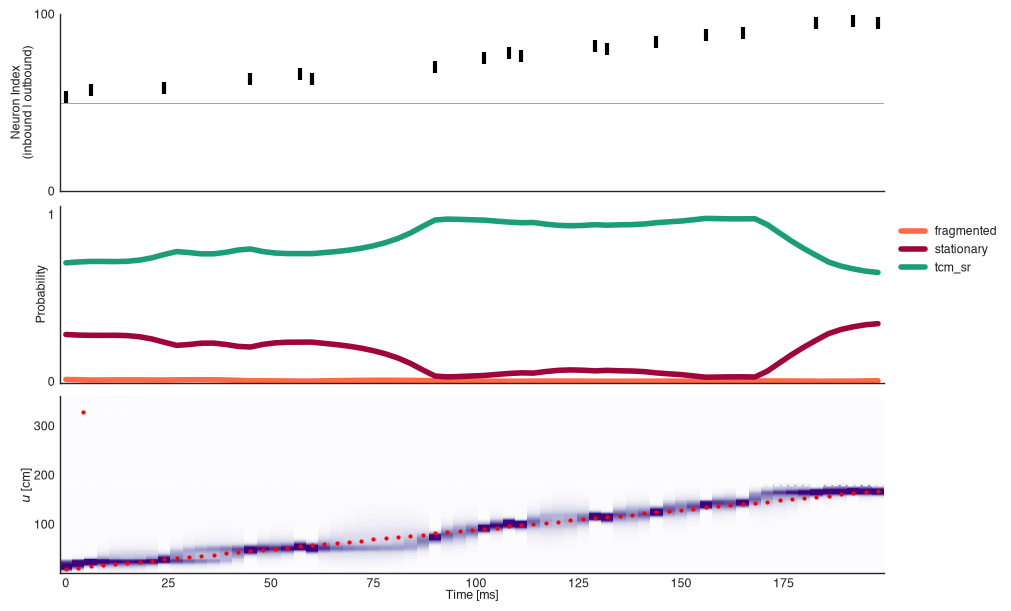

In [11]:
show(sweep_path(start_u=10.0), seed=1)

### Continuous, inbound

The same sweep run back towards the start, spiking the inbound neurons. It should decode on the inbound half of the loop, $u \in [180, 360]$.

17 spikes in 201 ms


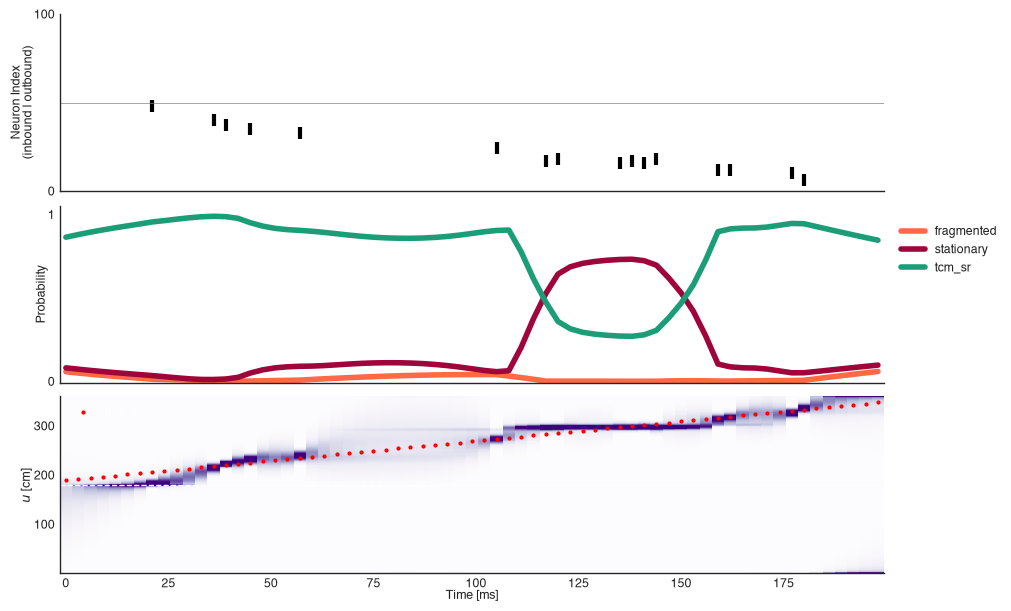

In [12]:
show(sweep_path(start_u=track_length + 10.0), seed=2)

### Stationary

14 spikes in 201 ms


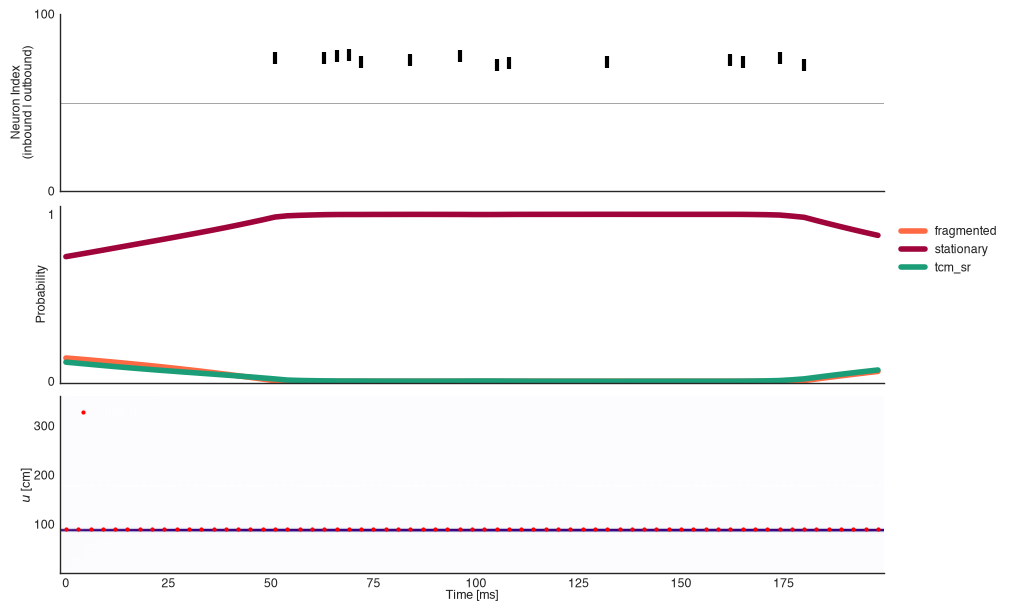

In [13]:
show(stationary_path(track_length / 2), seed=3)

### Fragmented

17 spikes in 201 ms


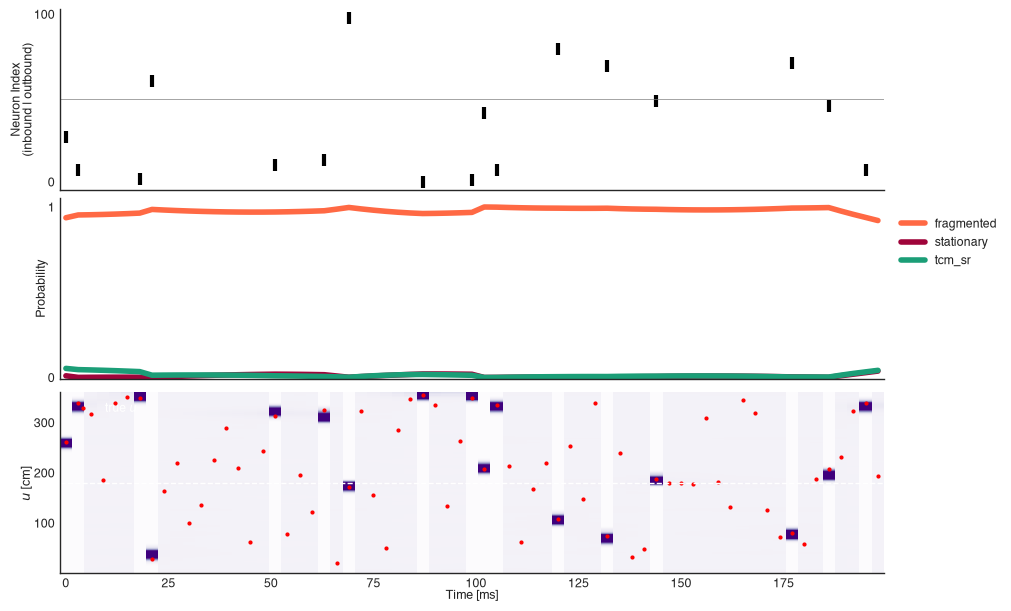

In [14]:
show(fragmented_path(np.random.default_rng(4)), seed=4)

### Stationary-Continuous-Stationary

41 spikes in 399 ms


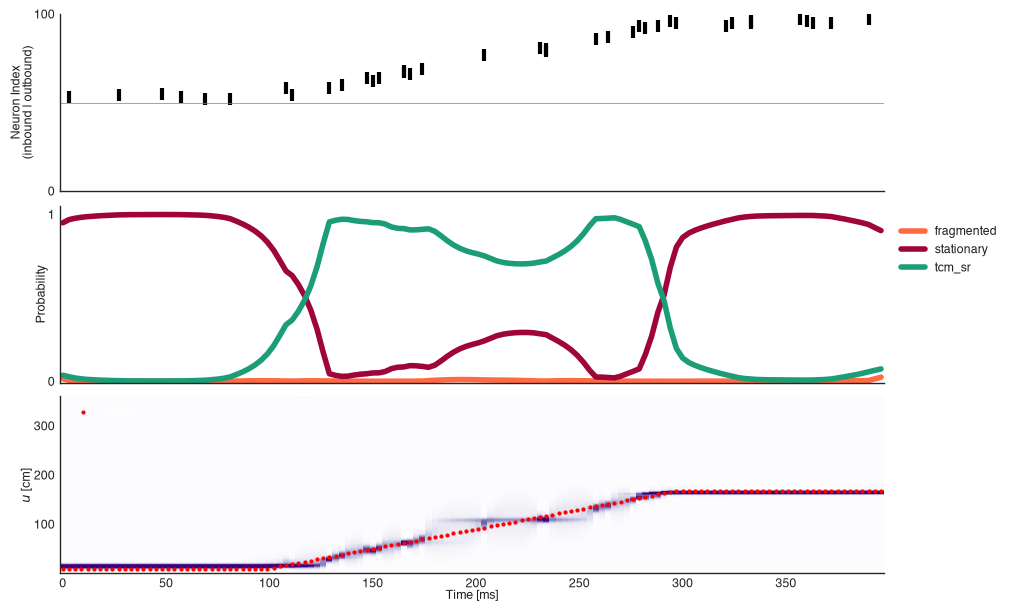

In [15]:
continuous_part = sweep_path(start_u=10.0)
show(np.concatenate([stationary_path(continuous_part[0], half), continuous_part,
                     stationary_path(continuous_part[-1], half)]), seed=5)

### Fragmented-Stationary-Fragmented

26 spikes in 399 ms


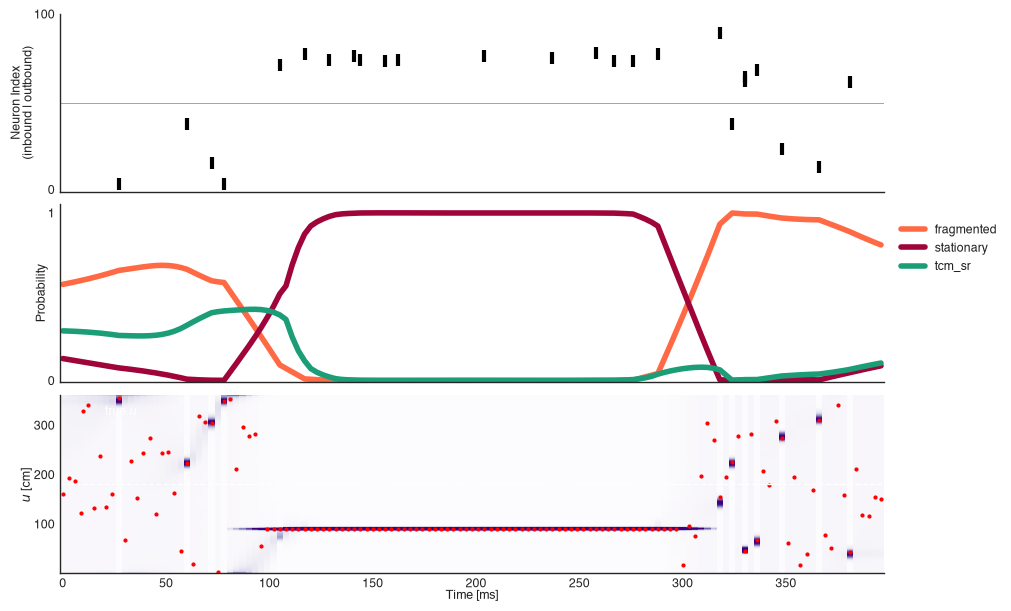

In [16]:
rng = np.random.default_rng(6)
show(np.concatenate([fragmented_path(rng, half), stationary_path(track_length / 2),
                     fragmented_path(rng, half)]), seed=6)

### Fragmented-Continuous-Fragmented

35 spikes in 399 ms


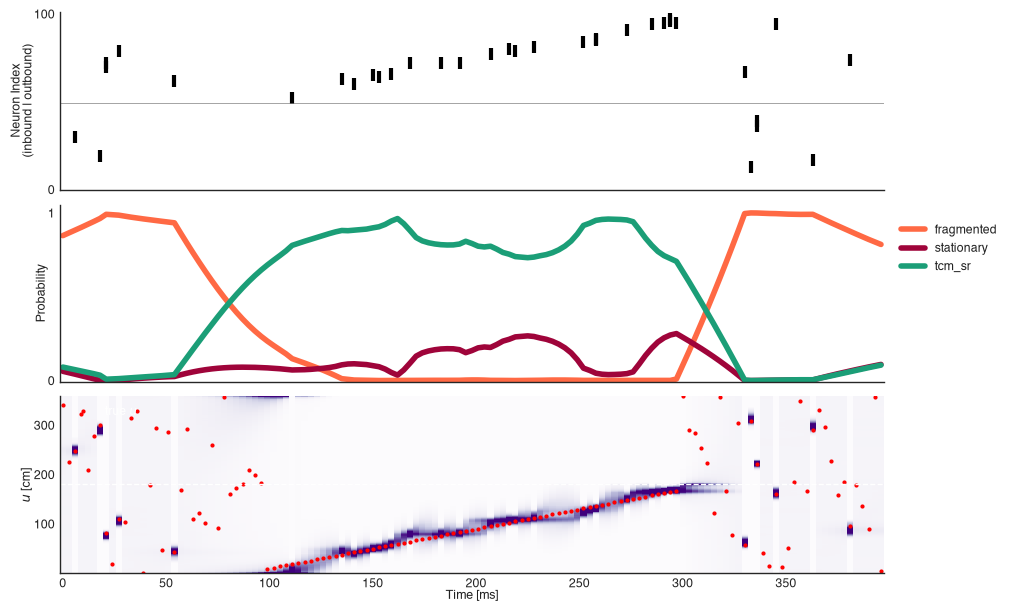

In [17]:
rng = np.random.default_rng(7)
show(np.concatenate([fragmented_path(rng, half), sweep_path(start_u=10.0),
                     fragmented_path(rng, half)]), seed=7)

### TCM-SR

A replay whose trajectory is sampled from the classifier's own `tcm_sr` kernel, one step per decoding bin.

21 spikes in 201 ms


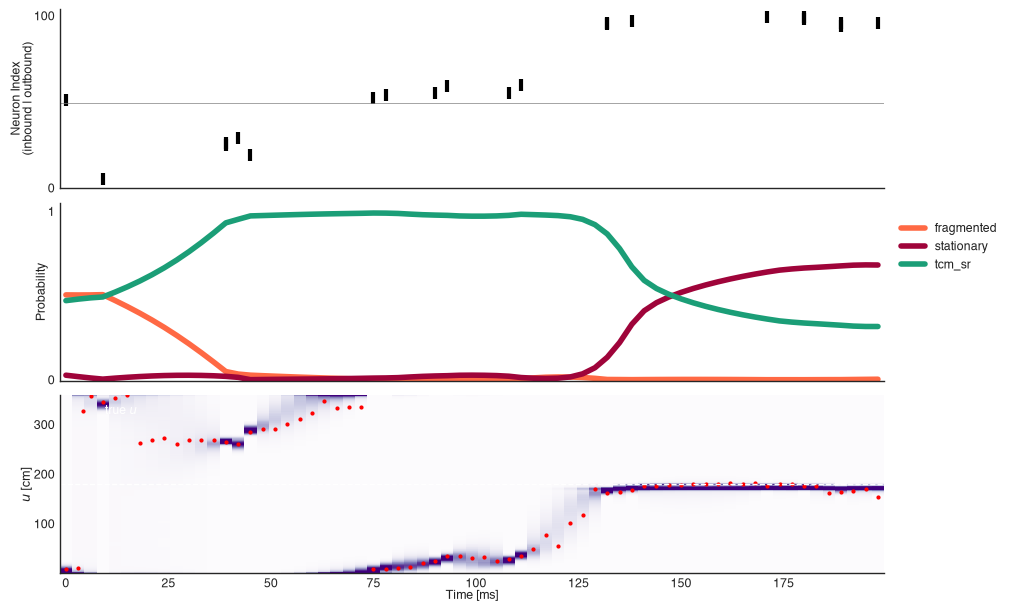

In [18]:
show(tcm_sr_path(10.0, np.random.default_rng(8)), seed=8)

### Stationary-TCMSR-Stationary

26 spikes in 399 ms


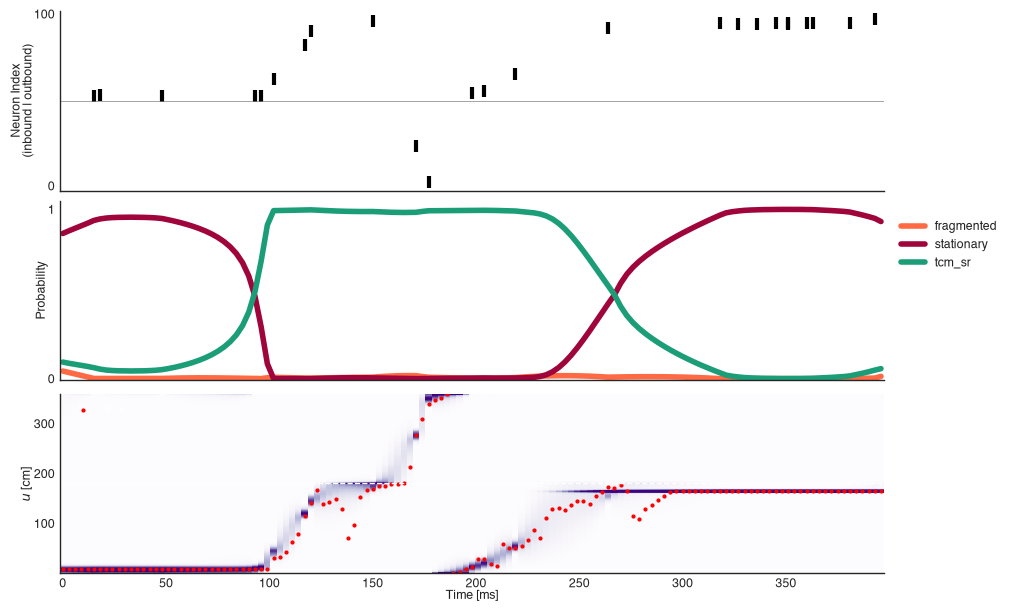

In [19]:
tcm_sr_part = tcm_sr_path(10.0, np.random.default_rng(9))
show(np.concatenate([stationary_path(tcm_sr_part[0], half), tcm_sr_part,
                     stationary_path(tcm_sr_part[-1], half)]), seed=9)

## Recovering the TCM-SR dynamic from TCM-SR replays

We generate many events from TCM-SR dynamics and from other dynamics, and the question is whether the classifier recovers the dynamic that generated each event.

* Each generator makes `N_RECOVERY_EVENTS` events of `EVENT_S`, from random start points, with spikes made as above:
  * `tcm_sr`: sampled from the classifier's own `tcm_sr` kernel.
  * `sweep`: the continuous replay.
  * `random jumps`: the fragmented replay.
  * `stationary`: one fixed position.
* Two classifiers decode them:
  * the 3-state `classifier` above;
  * a 4-state classifier, fit to the same run data, that adds a `RandomWalk` continuous state (the one from the reduction above). There `tcm_sr` also has to beat a generic continuous dynamic.

In [20]:
four_state_names = ['continuous', 'tcm_sr', 'fragmented', 'stationary']
four_state_row = [random_walk, tcm_sr, Uniform(), Identity()]
four_state_classifier = SortedSpikesClassifier(
    environments=Environment(place_bin_size=PLACE_BIN_SIZE_CM),
    continuous_transition_types=[four_state_row,
                                 four_state_row,
                                 [Uniform()] * 4,  # from fragmented
                                 four_state_row],
    sorted_spikes_algorithm='spiking_likelihood_kde',
    sorted_spikes_algorithm_params={'position_std': 3.0},
)
four_state_classifier.fit(directional_position, spikes)
# Both classifiers decode with the kernel the TCM-SR events are sampled from.
np.testing.assert_allclose(four_state_classifier.continuous_state_transition_[1, 1], tcm_sr_kernel)

recovery_classifiers = {
    '3-state': (classifier, state_names),
    '4-state (+RandomWalk)': (four_state_classifier, four_state_names),
}

In [21]:
import pandas as pd

from tcmsr_simulation import loop_distance as shared_loop_distance

GENERATORS = ['tcm_sr', 'sweep', 'random jumps', 'stationary']


def loop_distance(a, b):
    return shared_loop_distance(a, b, LOOP_LENGTH)


def generate_path(generator, seed):
    rng = np.random.default_rng(1000 + seed)
    start = rng.choice(interior_centers)
    if generator == 'tcm_sr':
        return tcm_sr_path(start, rng)
    if generator == 'sweep':
        return sweep_path(start)
    if generator == 'random jumps':
        return fragmented_path(rng)
    if generator == 'stationary':
        return stationary_path(start)


rows, examples = [], {}
for generator in GENERATORS:
    for seed in range(N_RECOVERY_EVENTS):
        true_u = generate_path(generator, seed)
        for classifier_name, (clf, names) in recovery_classifiers.items():
            event_time, test_spikes, results = classify(true_u, seed, clf, names)
            mean_probability = results.acausal_posterior.sum('position').mean('time').to_series()
            position_posterior = results.acausal_posterior.sum('state')
            map_u = position_posterior.position.values[position_posterior.values.argmax(axis=1)]
            rows.append({
                'classifier': classifier_name, 'generator': generator, 'seed': seed,
                'n_spikes': test_spikes.sum(), 'winner': mean_probability.idxmax(),
                **{f'P({state})': p for state, p in mean_probability.items()},
                'median position error (cm)': np.median(loop_distance(map_u, true_u)),
            })
            if generator == 'tcm_sr' and classifier_name == '3-state':
                examples[seed] = (event_time, test_spikes, true_u, results)
recovery = pd.DataFrame(rows)

print(f'spikes per event: {recovery.n_spikes.mean():.1f} on average')
for classifier_name, table in recovery.groupby('classifier', sort=False):
    print(f'{classifier_name}: events won by each state, out of {N_RECOVERY_EVENTS}')
    display(pd.crosstab(table.generator, table.winner).loc[GENERATORS])
    probability_columns = [f'P({state})' for state in recovery_classifiers[classifier_name][1]]
    print(f'{classifier_name}: mean over events')
    display(table.groupby('generator', sort=False)[
        probability_columns + ['median position error (cm)']].mean().round(2))

spikes per event: 15.2 on average
3-state: events won by each state, out of 20


winner,fragmented,stationary,tcm_sr
generator,,,
tcm_sr,0,0,20
sweep,0,0,20
random jumps,19,0,1
stationary,0,20,0


3-state: mean over events


,P(tcm_sr),P(fragmented),P(stationary),median position error (cm)
generator,,,,
tcm_sr,0.91,0.04,0.05,8.4
sweep,0.80,0.02,0.18,7.1
random jumps,0.08,0.88,0.04,73.2
stationary,0.01,0.01,0.98,1.0


4-state (+RandomWalk): events won by each state, out of 20


winner,continuous,fragmented,stationary,tcm_sr
generator,,,,
tcm_sr,0,0,0,20
sweep,7,0,0,13
random jumps,0,19,0,1
stationary,1,0,19,0


4-state (+RandomWalk): mean over events


,P(continuous),P(tcm_sr),P(fragmented),P(stationary),median position error (cm)
generator,,,,,
tcm_sr,0.03,0.91,0.03,0.03,8.4
sweep,0.36,0.56,0.01,0.07,4.1
random jumps,0.02,0.06,0.89,0.02,71.8
stationary,0.16,0.01,0.01,0.82,1.1


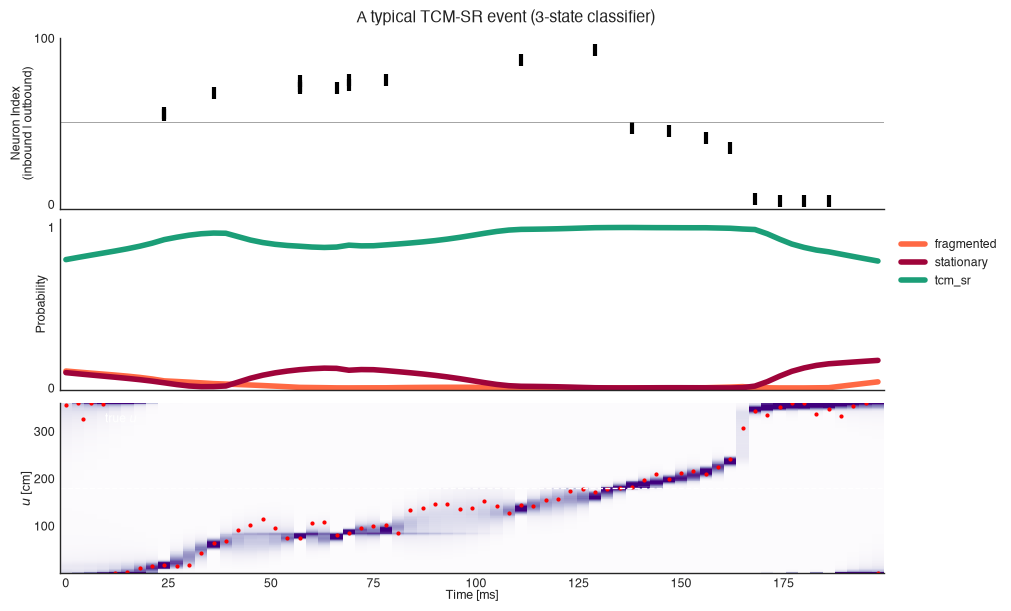

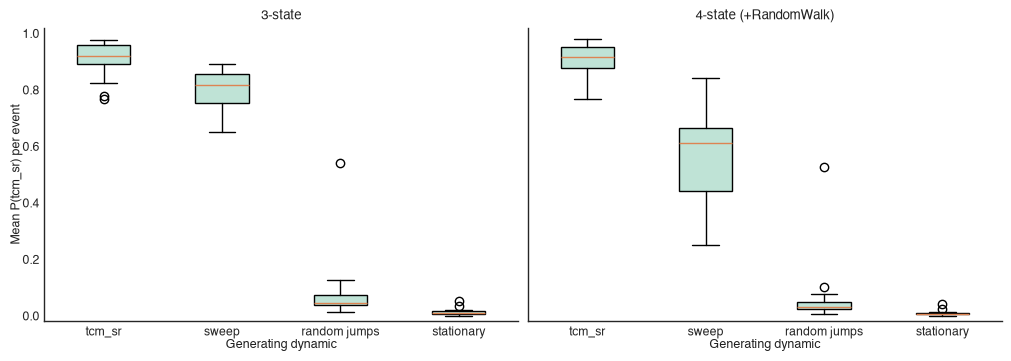

In [22]:
# The TCM-SR event with the median P(tcm_sr) under the 3-state classifier.
tcm_sr_events = recovery[(recovery.generator == 'tcm_sr') & (recovery.classifier == '3-state')]
median_seed = tcm_sr_events.sort_values('P(tcm_sr)').seed.iloc[len(tcm_sr_events) // 2]
event_time, test_spikes, true_u, results = examples[median_seed]
plot_classification(event_time, test_spikes, results, true_u=true_u)
plt.suptitle('A typical TCM-SR event (3-state classifier)')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True, constrained_layout=True)
for ax, (classifier_name, table) in zip(axes, recovery.groupby('classifier', sort=False)):
    ax.boxplot([table[table.generator == g]['P(tcm_sr)'] for g in GENERATORS],
               patch_artist=True, boxprops=dict(facecolor='#bfe3d6'))
    ax.set_xticks(range(1, len(GENERATORS) + 1), GENERATORS)
    ax.set_title(classifier_name)
    ax.set_xlabel('Generating dynamic')
axes[0].set_ylabel('Mean P(tcm_sr) per event')
axes[0].set_ylim((-0.02, 1.02))
sns.despine()

**Results with the default settings** (about 15 spikes per event, `gamma=0.8`):

* **TCM-SR is recovered.** The 3-state classifier assigns all 20 TCM-SR events and all 20 sweeps to `tcm_sr`, all 20 stationary events to `stationary`, and 19 of 20 random-jump events to `fragmented` (one goes to `tcm_sr`). Mean P(tcm_sr) is 0.91 on TCM-SR events and 0.08 on random jumps.
* **The TCM-SR paths are tracked.** The median position error is about 8 cm.
* **`tcm_sr` and `continuous` are only partly separable on constant-speed sweeps.** In the 4-state classifier, TCM-SR events still go to `tcm_sr` (20 of 20, mean P 0.91, with 0.03 to `continuous`). Sweeps split: 13 of 20 go to `tcm_sr` and 7 to `continuous` (mean P 0.56 against 0.36). The forward-biased kernel learned from the laps fits a forward sweep about as well as the symmetric `RandomWalk`. A `tcm_sr` label means sequential, behavior-like replay, which can include constant-speed sweeps.
* **Stationary events are classified correctly** (20 of 20 in the 3-state classifier, 19 of 20 in the 4-state one).